# Schottky Barrier Height Fitting, Cheung Methods

2026/5/13

This notebook shows only basic usage of `HDF5Analyzer` module and proof-of-concept for cheung method

More advanced functions and details defined in another notebook, `cheung_fit_tests.ipynb`, which includes multiple curves, sliding windows etc.

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib_scalebar.scalebar import ScaleBar

# 設置 matplotlib 使用 Arial 字體
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 12,
    'axes.labelsize': 18,
    'axes.titlesize': 18,
    'axes.titleweight': 'bold',
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'figure.titlesize': 20,
    'figure.titleweight': 'bold'
})

import h5py
import sys
from pathlib import Path

import os

# 導入模組
from ivs_tools.io.h5utils import HDF5Analyzer
#from ivs_tools.physics.schottky_analyzer import SchottkyAnalyzer

root_path  ='/home/tim/Documents/AS/data/nanonis2/2024/20240508/2 um 100 pix bias spec map2'
filename = "2 um 100 pix bias spec map2.h5"

h5map_path = os.path.join(root_path, filename)

# 初始化 (自動載入)
h5map = HDF5Analyzer(h5map_path)

# 查看結構
h5map.list_structure()

# 取得摘要
print("\nSummary:")
summary = h5map.summary()

h5map.print_usage()

DATASET: bias (Shape: (500,), Dtype: float64)
DATASET: current_fwd (Shape: (500, 10000), Dtype: float64)

METADATA:
  Experiment: Bias-Spectroscopy-Current-Map-fwd
  Bias Points: 500
  Pixels: 100 x 100
  Range: 2.00e-06 x 2.00e-06 m

Summary:
📋 數據摘要
----------------------------------------
文件: 2 um 100 pix bias spec map2.h5
路徑: /home/tim/Documents/AS/data/nanonis2/2024/20240508/2 um 100 pix bias spec map2/2 um 100 pix bias spec map2.h5

📐 空間維度:
  X方向像素: 100
  Y方向像素: 100

⚡ 偏壓維度:
  偏壓點數: 500
  偏壓範圍: -2.000 到 2.000 V

💾 數據陣列:
  Current Map: (500, 10000) (float64)
    總大小: 38.15 MB
    範圍: -4.328e-05 到 3.409e-05 A
  Bias Vector: (500,) (float64)
----------------------------------------
HDF5Analyzer 使用指南

📁 數據屬性:
----------------------------------------
  • filepath: 未加載或不可用
  • metadata: 未加載或不可用
  • current_map: 未加載或不可用
  • bias_vector: 未加載或不可用

⚙️ 主要方法:
----------------------------------------
  • load_metadata(): 加載元數據
  • load_current_map(): 加載電流映射
  • load_bias_vector(): 加載偏壓序列
  • l

成功載入文件: /home/tim/Documents/AS/data/nanonis2/2024/20240508/2 um 100 pix bias spec map2/2 um 100 pix bias spec map2.h5

Testing Point 1: (x=87, y=79)


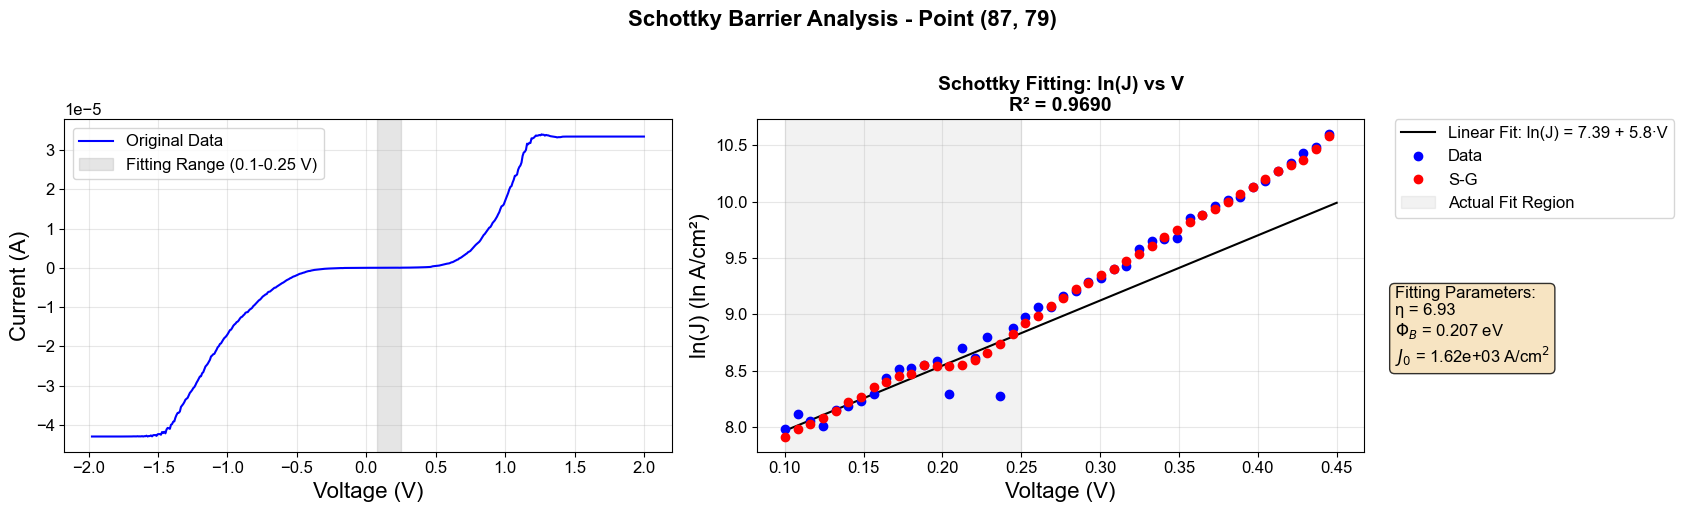

In [2]:
from scipy.signal import savgol_filter

# 載入 HDF5 數據
h5map = HDF5Analyzer(h5map_path)
print(f"成功載入文件: {h5map_path}")

# 選擇一個點進行測試
test_points = [(87, 79)]

for point_idx, (x, y) in enumerate(test_points):
    print(f"\n{'='*60}")
    print(f"Testing Point {point_idx+1}: (x={x}, y={y})")
    print('='*60)
    
    # 獲取 spectrum (跳過前面3個點)
    spectrum = h5map.get_spectrum_at_pixel(x, y)
    bias_vector = h5map.bias_vector
    
    #fit_ranges = [(0.10, 0.25)]
    
    d = 25 # diameter, nm
    A_eff = np.pi*(d/2)**2*1e-14 # cm^2
    
    current_density = spectrum / A_eff
    
    mask_fit = (bias_vector >= 0.1) & (bias_vector <= 0.25)
    mask_view = (bias_vector >= 0.1) & (bias_vector <= 0.45) # 觀察用
    valid_mask = mask_view & (current_density > 0)

    # S-G filter
    window_length = 13 
    poly_order = 3
    
    # It's usually best to filter the raw current before taking the log
    current_density_sg = savgol_filter(current_density, window_length, poly_order)
    
    J_fit = current_density_sg[mask_fit]
    V_fit = bias_vector[mask_fit]
    
    # positivity
    pos_idx = J_fit > 0
    V_final = V_fit[pos_idx]
    ln_J_final = np.log(J_fit[pos_idx])

    from scipy import stats
    slope, intercept, r_value, p_value, std_err = stats.linregress(V_final, ln_J_final)
    r_squared = r_value**2
   
# skip 3 pixels
start_idx = 3
spectrum_trimmed = spectrum[start_idx:]
bias_trimmed = bias_vector[start_idx:]

fig, axes = plt.subplots(1,2,figsize = (17,5))

axes[0].plot(bias_trimmed, spectrum_trimmed, 'b-', linewidth=1.5, label='Original Data')
axes[0].axvspan(0.08, 0.250, alpha=0.2, color='gray', label='Fitting Range (0.1-0.25 V)')
#axes[0].set_xlim(0, 0.4)
axes[0].set_xlabel('Voltage (V)', fontsize=16)
axes[0].set_ylabel('Current (A)', fontsize=16)
#axes[0].set_title(f'I-V Curve with Fitting Range\nContact Area: {area_cm2:.2e} cm²', fontsize=14)
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=12)
axes[0].tick_params(axis='both', which='major', labelsize=12)

# 繪製擬合線
V_fit_line = np.linspace(V_final.min(), 0.45, 200)
ln_J_fit_line = intercept + slope * V_fit_line

#axes[1].plot(bias_vector[mask_view], np.log(current_density[mask_view]), 'bo', label='Data')
axes[1].plot(V_fit_line, ln_J_fit_line, 'k-', label=f'Linear Fit: ln(J) = {intercept:.2f} + {slope:.1f}·V')
axes[1].plot(bias_vector[valid_mask], 
             np.log(current_density[valid_mask]), 
             'bo', label='Data')
axes[1].plot(bias_vector[mask_view], 
             np.log(current_density_sg[mask_view]), 
             'ro', label='S-G')

axes[1].axvspan(0.1, 0.25, color='gray', alpha=0.1, label='Actual Fit Region')

axes[1].set_xlabel('Voltage (V)', fontsize=16)
axes[1].set_ylabel('ln(J) (ln A/cm²)', fontsize=16)
axes[1].set_title(f'Schottky Fitting: ln(J) vs V\nR² = {r_squared:.4f}', fontsize=14)
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=12, loc='upper left', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
axes[1].tick_params(axis='both', which='major', labelsize=12)


# 計算 Schottky 參數並檢查
V_T = 0.025  # 300K 時的熱電壓
ideality_factor = 1 / (slope * V_T)

# Richardson constant for MoS2
A_star = 54  # A/cm²K²  
T = 300.0  # K
k = 8.617333262145e-5  # eV/K

J0 = np.exp(intercept)
phi_B = k * T * np.log(A_star * T**(2) / J0)

# 添加參數文本框
param_text = (f"Fitting Parameters:\n"
              f"η = {ideality_factor:.2f}\n"
              fr"$\Phi_B$ = {phi_B:.3f} eV" # Added 'r' here
              f"\n$J_0$ = {J0:.2e} A/cm$^2$" # Fixed 'J0' line too
              )

axes[1].text(1.05, 0.5, param_text,
                transform=axes[1].transAxes,
                fontsize=12,
                verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

plt.suptitle(f'Schottky Barrier Analysis - Point ({x}, {y})', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()


## Mutli and Single Point I-V

In [3]:
import matplotlib.pyplot as plt
import numpy as np

def plot_multiple_iv(h5map, points, layer_num): # 記得把 layer_num 傳進去
    fig, ax = plt.subplots(1, 1, figsize=(8, 5))
    
    bias = h5map.bias_vector[3:]
    
    # 使用 zip 同時取得坐標與對應的層數
    for (px, py), layer in zip(points, layer_num):
        current = h5map.get_spectrum_at_pixel(px, py)[3:]
        
        # 在 label 中加入 layer 變數
        ax.plot(bias, np.abs(current), 'o', alpha=0.7, markersize=6, 
                label=f'{layer}L: ({px}, {py})')

    # 設定圖表格式
    ax.set_yscale('log')
    ax.set_xlabel('Voltage (V)', fontsize=16)
    ax.set_ylabel('Current (A) ', fontsize=16)
    ax.set_title('Comparison of I-V Curves at Different Points', fontsize=16)
    ax.tick_params(labelsize=12)
    ax.grid(True, which="both", ls="-", alpha=0.4)
    ax.set_xlim(-0.02, 1.8)
    
    # 加入 Legend
    ax.legend(loc='lower right', fontsize=12)
    
    plt.tight_layout()

    return fig, ax

def plot_iv(bias, current, logy=True):
    fig, ax = plt.subplots(1, 1, figsize=(8, 5))
    
    if logy:
        ax.plot(bias, np.abs(current), 'bo', alpha=0.7, lw= 3, label='Raw Data')
        ax.set_yscale('log') # 建議用對數坐標觀察
    else:
        ax.plot(bias, current, 'b-', alpha=0.7, lw= 3, label='Raw Data')
        
    ax.set_xlabel('Voltage (V)', fontsize = 15)
    ax.set_ylabel('Current (A)', fontsize = 15)
    #ax.set_title(f'Point ({x}, {y}) Raw I-V', fontsize = 15)
    ax.tick_params(labelsize = 12)
    ax.grid(True, which="both", ls="-", alpha=0.4)
    ax.set_xlim(0, 1.2)

    return fig, ax
    

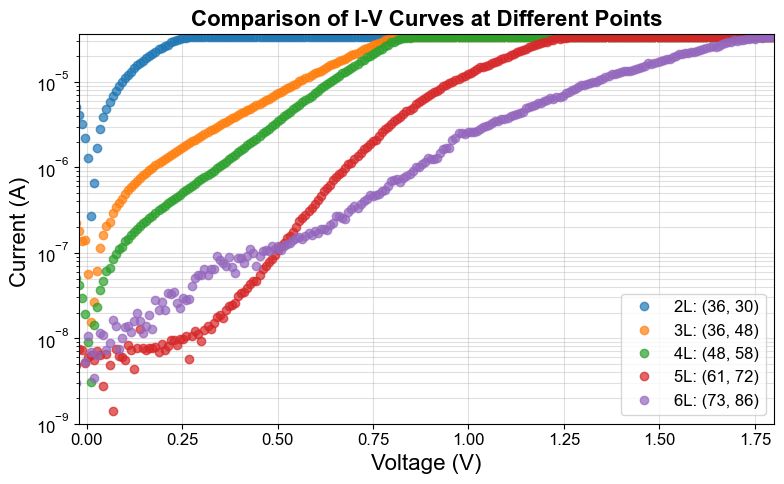

In [4]:
# 定義目標點
points = [(36, 30), (36, 48), (48, 58), (61, 72), (73, 86)]

layer_num = np.arange(2,7)

fig, ax = plot_multiple_iv(h5map, points, layer_num)
ax.set_ylim(1e-9, 3.6e-5)

plt.tight_layout()
plt.savefig(h5map_path[:-4] + '_semilog_compare.png', dpi = 300, bbox_inches = 'tight')

plt.show()

## Current Limits

In [5]:
def get_cur_limits(analyzer):

    x0, y0 = 35, 53
    spectrum = analyzer.get_spectrum_at_pixel(x0, y0)[3:] 
    bias = analyzer.bias_vector[3:]

    cur_high = np.mean(spectrum[-20:])
    cur_low = np.mean(spectrum[:20])

    return {'cur_low': cur_low, 'cur_high': cur_high}
    

In [6]:
get_cur_limits(h5map)

{'cur_low': np.float64(-4.287904915e-05),
 'cur_high': np.float64(3.3431847099999994e-05)}

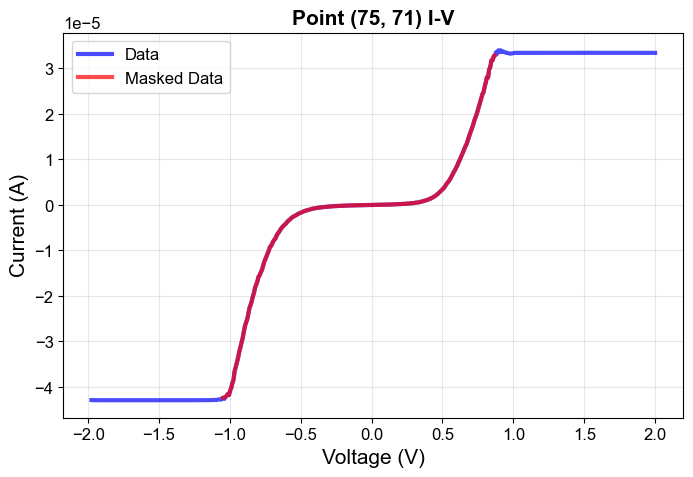

In [7]:

fig, ax = plt.subplots(1, 1, figsize=(8, 5))

xs, ys = 75, 71
spectrum = h5map.get_spectrum_at_pixel(xs, ys)[3:] 
bias = h5map.bias_vector[3:]

cur_low = get_cur_limits(h5map)['cur_low']
cur_high = get_cur_limits(h5map)['cur_high']
mask = (spectrum > (cur_low + 5e-7)) & (spectrum < (cur_high - 5e-7))

ax.plot(bias, spectrum, 'b-', alpha=0.7, lw= 3, label='Data')
ax.plot(bias[mask], spectrum[mask], 'r-', alpha=0.7, lw= 3, label='Masked Data')

ax.set_xlabel('Voltage (V)', fontsize = 15)
ax.set_ylabel('Current (A)', fontsize = 15)
ax.set_title(f'Point ({xs}, {ys}) I-V', fontsize = 15)
ax.tick_params(labelsize = 12)
ax.grid(True, which="both", ls="-", alpha=0.3)
plt.legend(fontsize = 12)

plt.savefig(f'{h5map_path[:-4]}_{xs}, {ys}_masked_current_limits_.png', dpi = 300, bbox_inches = 'tight')
plt.show()

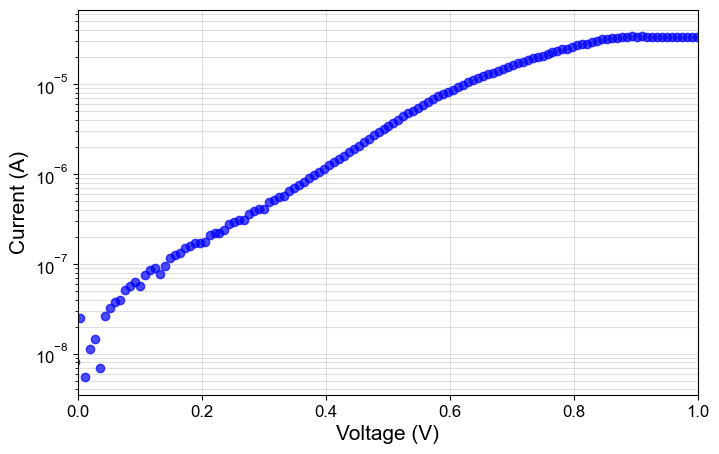

In [8]:
fig, ax = plot_iv(bias, spectrum)
ax.set_xlim(0,1)
plt.show()
#print(f'spectrum {x} {y}: current min {spectrum.min()} max {spectrum.max()}')

## Cheung Method

1. 物理背景與公式根據熱電子發射理論（Thermionic Emission Theory），流經肖特基接面的電流 $I$
   根據熱電子發射理論，電流公式為：$$I = AA^*T^2 \exp\left( \frac{-q\Phi_b}{kT} \right) \exp\left( \frac{q(V - IR_s)}{nkT} \right)$$當我們對兩邊取對數並整理 $V$ 時，會得到：$$V = IR_s + n\Phi_b + \frac{nkT}{q} \ln\left( \frac{I}{AA^*T^2} \right)$$這時候定義 $H(I)$：$$H(I) \equiv V - \left( \frac{nkT}{q} \right) \ln\left( \frac{I}{AA^*T^2} \right)$$將上面的 $V$ 代入，公式會簡化為：$$H(I) = n\Phi_b + IR_s$$

   其中 $I_s$ 為飽和電流，$R_s$ 是中性區與接觸產生的串聯電阻。當 $V > 3kT/q$ 時，Cheung 提出了兩個函數來線性化處理數據。
---

### Method A, B

I. 函數 A：提取 $R_s$ 與 $n$定義函數 $H(I)$ 如下：$$H(I) = V - \left( \frac{nkT}{q} \right) \ln\left( \frac{I}{AA^*T^2} \right)$$經過推導，可得線性關係式：$$H(I) = n\Phi_b + IR_s$$

II. 函數 B：輔助驗證定義另一個函數 $dV/d(\ln I)$：$$\frac{dV}{d(\ln I)} = \frac{nkT}{q} + IR_s$$

1. 第一步：繪製 $\frac{dV}{d(\ln I)}$ vs. $I$ 圖斜率 (Slope): 代表串聯電阻 $R_s$。截距 (Intercept): 代表 $\frac{nkT}{q}$，由此可計算出理想因子 $n$。這一步不依賴能障高度，因此非常穩定。
2. 第二步：繪製 $H(I)$ vs. $I$ 圖利用第一步得到的 $n$，計算出每個電流點對應的 $H(I)$。斜率 (Slope): 同樣代表 $R_s$（可用來與第一步比對，增加準確性）。截距 (Intercept): 代表 $n\Phi_b$，由此計算出能障高度 $\Phi_b$。

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.signal import savgol_filter

import pandas as pd

def preprocess_data(current):
    # 先轉成 Series 方便處理
    s = pd.Series(np.abs(current))
    
    # Step 1: Rolling Median 去除突波
    # 使用 bfill (後向填補) 和 ffill (前向填補) 取代舊有的 fillna(method=...)
    s_median = s.rolling(window=7, center=True).median().bfill().ffill()
    
    # Step 2: Savitzky-Golay 平滑
    # window_length 視數據密度調整，必須為奇數
    smoothed_I = savgol_filter(s_median, window_length=31, polyorder=3)
    
    return smoothed_I
    
def cheung_analysis(bias, current, area_cm2, T=300, a_star=54.0):
    # 物理常數
    k_B = 8.617333e-5
    q = 1.6021766e-19
    V_T = (1.380649e-23 * T) / q
    
    # 1. 預處理：濾波並轉為電流密度 J 與電流 I
    I_smooth = preprocess_data(current)
    
    # 2. 計算微分 dV / d(ln I)
    ln_I = np.log(I_smooth)
    dv = np.gradient(bias)
    dlnI = np.gradient(ln_I)
    y_func_a = dv / dlnI  # 方法 A 的 Y 軸
    
    # --- 方法 A 擬合 (選擇高電流區，即進入電阻支配區) ---
    mask_a = (bias > 0.5) & (bias < 0.8)
    slope_a, intercept_a, r_a, _, _ = stats.linregress(I_smooth[mask_a], y_func_a[mask_a])
    if r_a**2 < 0.95:
        print("警告：方法 A 的線性擬合度較低，提取的 Rs 與 n 可能不準確。")
    
    Rs_a = slope_a  # 單位: Ohms
    n_a = intercept_a / V_T
    
    # --- 方法 B 擬合 ---
    # H(I) = V - n * V_T * ln(I / (A * A* * T^2))
    constant_term = area_cm2 * a_star * (T**2)
    H_I = bias - (n_a * V_T * np.log(I_smooth / constant_term))
    
    slope_b, intercept_b, r_b, _, _ = stats.linregress(I_smooth[mask_a], H_I[mask_a])
    if r_b**2 < 0.95:
        print("警告：方法 B 的線性擬合度較低，提取的 Rs 與 phi_b 可能不準確。")
        
    Rs_b = slope_b
    phi_b = intercept_b / n_a  # 修正後的障礙高度
    
    return {
        'bias': bias, 'I': I_smooth, 'y_a': y_func_a, 'H_I': H_I, 'mask': mask_a,
        'Rs_a': Rs_a, 'n_a': n_a, 'r2_a': r_a**2,
        'Rs_b': Rs_b, 'phi_b': phi_b, 'r2_b': r_b**2
    }

def plot_focused_cheung(ax, x_data, y_data, mask, slope, intercept, title, ylabel, result_text):
    # 畫出所有點 
    ax.scatter(x_data, y_data, c='gray', s=50, alpha=1, label='Other Data')
    
    # 畫出擬合區間點 (深色)
    ax.scatter(x_data[mask], y_data[mask], c='tab:red' if 'A' in title else 'tab:blue', 
               s=25, label='Fitting Range', zorder=3)
   
    # 畫出擬合線
    fit_x = np.linspace(x_limit[0], x_limit[1], 150)
    fit_y = slope * fit_x + intercept
    ax.plot(fit_x, fit_y, 'k--', lw=2, label='Linear Fit', zorder=4)
    
    # 自動縮放 Y 軸：只看擬合點附近的 Y 範圍
    y_visible = y_data[mask]
    y_margin = (y_visible.max() - y_visible.min()) * 0.3
    ax.set_ylim(y_visible.min() - y_margin, y_visible.max() + y_margin)
    ax.set_xlim(x_limit)
    
    ax.set_title(title, fontsize=15, fontweight='bold')
    ax.set_xlabel('Current I (A)', fontsize=14)
    ax.set_ylabel(ylabel, fontsize=14)
    ax.legend(loc='best', frameon=True, fontsize = 12)
    ax.grid(True, ls='--', alpha=0.6)
    ax.tick_params(labelsize = 12)
    
    # 標註結果
    ax.text(0.05, 0.85, result_text, transform=ax.transAxes, 
            bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'),fontsize = 12)
    

圖表已儲存至: analysis_results/schottky_plots/point_75_71_cheung_method.png


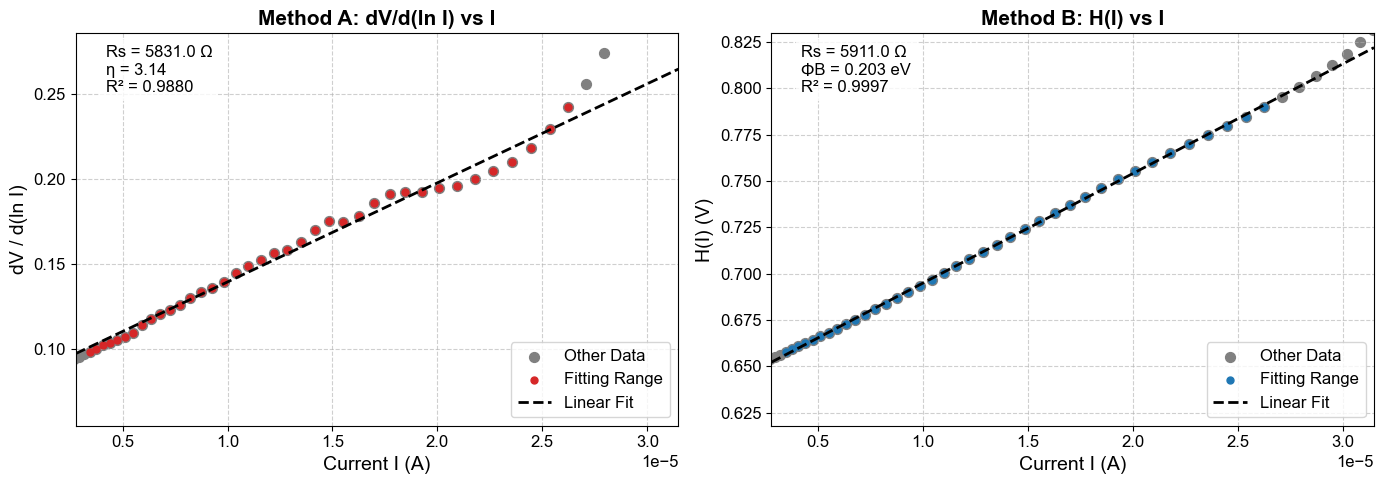

In [7]:
# 執行分析

d_nm = 25
area_cm2 = np.pi * (d_nm/2 * 1e-7)**2

xs, ys = 75, 71
spectrum = h5map.get_spectrum_at_pixel(xs, ys)[3:] 
bias = h5map.bias_vector[3:]

res = cheung_analysis(bias, spectrum, area_cm2)

# --- 繪圖優化：聚焦於擬合區間 ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 設定 X 軸範圍 (緩衝區間：擬合範圍的 80% ~ 120%)
i_min, i_max = res['I'][res['mask']].min(), res['I'][res['mask']].max()
x_limit = (i_min * 0.8, i_max * 1.2)

# 準備標註文字
text_a = f"Rs = {res['Rs_a']:.1f} Ω\nη = {res['n_a']:.2f}\nR² = {res['r2_a']:.4f}"
text_b = f"Rs = {res['Rs_b']:.1f} Ω\nΦB = {res['phi_b']:.3f} eV\nR² = {res['r2_b']:.4f}"

# 執行局部繪圖
plot_focused_cheung(ax1, res['I'], res['y_a'], res['mask'], res['Rs_a'], 
                    res['n_a']*0.02585, 'Method A: dV/d(ln I) vs I', 'dV / d(ln I)', text_a)

plot_focused_cheung(ax2, res['I'], res['H_I'], res['mask'], res['Rs_b'], 
                    res['n_a'] * res['phi_b'], 'Method B: H(I) vs I', 'H(I) (V)', text_b)

plt.tight_layout()

from pathlib import Path

# 設定儲存路徑
save_dir = Path("analysis_results/schottky_plots")
save_dir.mkdir(parents=True, exist_ok=True) # 自動建立資料夾

file_name = f"point_{xs}_{ys}_cheung_method.png"
save_path = save_dir / file_name

plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"圖表已儲存至: {save_path}")

plt.show()

(-1.2, 1.2)

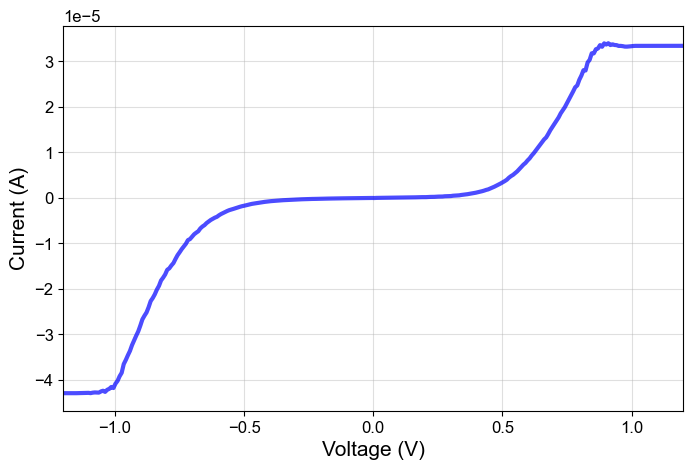

In [8]:

fig, ax = plot_iv(bias, spectrum, False)
ax.set_xlim(-1.2, 1.2)